# Notebook 06 — Exploratory Data Analysis

**AI Evolution Map · Data Pipeline**

---

## Purpose

Explore the validated datasets to understand their structure, distributions,
coverage, and trends. All findings here are **descriptive** — we distinguish
observation from interpretation and never claim causation from charts.

**Data source**: `data/processed/` — validated records only.

**Questions explored:**
1. How are records distributed across publication years?
2. What are the most common AI research categories?
3. What is the distribution of model downloads on Hugging Face?
4. Which years have the most missing data?
5. How do the three sources compare in coverage?

In [1]:
import sys
from pathlib import Path

project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

PROCESSED_DIR = project_root / 'data' / 'processed'

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

def load_processed(filename: str) -> list[dict]:
    path = PROCESSED_DIR / filename
    if not path.exists():
        print(f'WARNING: {filename} not found. Run Notebooks 04 and 05 first.')
        return []
    with open(path, encoding='utf-8') as f:
        return json.load(f)

print('EDA setup complete.')

EDA setup complete.


In [2]:
# Load validated datasets
oa_records = load_processed('openalex_works_validated.json')
arxiv_records = load_processed('arxiv_papers_validated.json')
hf_records = load_processed('huggingface_models_validated.json')

df_oa = pd.DataFrame(oa_records) if oa_records else pd.DataFrame()
df_arxiv = pd.DataFrame(arxiv_records) if arxiv_records else pd.DataFrame()
df_hf = pd.DataFrame(hf_records) if hf_records else pd.DataFrame()

print(f'Loaded: OpenAlex={len(df_oa)}, arXiv={len(df_arxiv)}, HF={len(df_hf)}')

Loaded: OpenAlex=25, arXiv=25, HF=25


## EDA 1: Publication Year Distributions

**Caveat**: These are SAMPLE counts from our 100-record ingestion, not population counts.
The real publication numbers are orders of magnitude larger. Do not cite these as
global AI publication statistics.

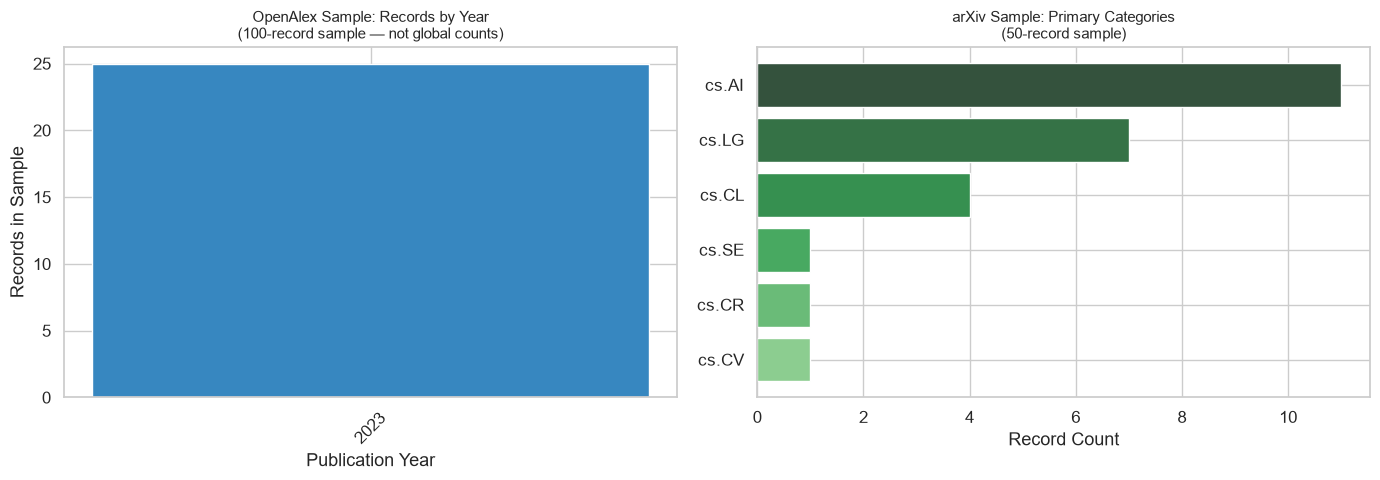

In [3]:
if not df_oa.empty and 'year' in df_oa.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # OpenAlex year distribution
    oa_years = df_oa['year'].value_counts().sort_index()
    axes[0].bar(oa_years.index.astype(str), oa_years.values,
                color=sns.color_palette('Blues_d', len(oa_years)))
    axes[0].set_title('OpenAlex Sample: Records by Year\n(100-record sample — not global counts)', fontsize=11)
    axes[0].set_xlabel('Publication Year')
    axes[0].set_ylabel('Records in Sample')
    axes[0].tick_params(axis='x', rotation=45)

    # arXiv category distribution
    if not df_arxiv.empty and 'primary_category' in df_arxiv.columns:
        cat_counts = df_arxiv['primary_category'].value_counts().head(10)
        axes[1].barh(cat_counts.index[::-1], cat_counts.values[::-1],
                    color=sns.color_palette('Greens_d', len(cat_counts)))
        axes[1].set_title('arXiv Sample: Primary Categories\n(50-record sample)', fontsize=11)
        axes[1].set_xlabel('Record Count')

    plt.tight_layout()
    plt.savefig('../docs/eda_distributions.png', dpi=100)
    plt.show()

## EDA 2: Hugging Face Download Distribution

Download counts are heavily right-skewed — a handful of models dominate.
This is expected: the HF Hub is sorted by downloads, so our sample is
not representative of the full model population.

HF Model Downloads — Summary Statistics:
count    2.500000e+01
mean     6.640778e+06
std      5.125563e+06
min      2.891100e+06
25%      3.970913e+06
50%      4.864172e+06
75%      6.369723e+06
max      2.515803e+07
Name: downloads, dtype: float64


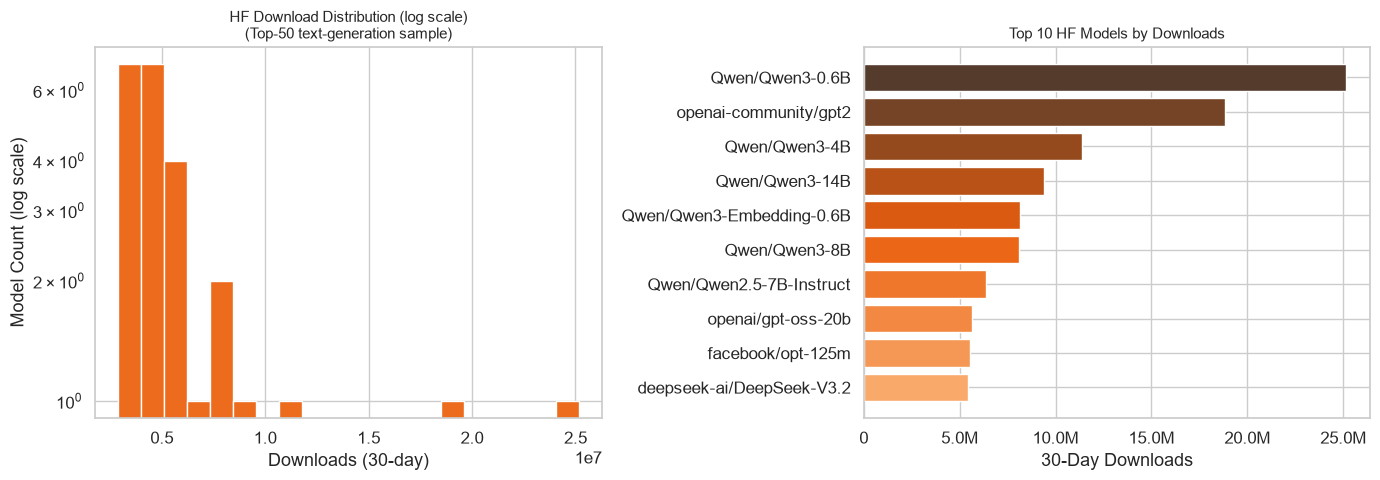

In [4]:
if not df_hf.empty and 'downloads' in df_hf.columns:
    downloads = df_hf['downloads'].dropna()

    print('HF Model Downloads — Summary Statistics:')
    print(downloads.describe())

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Log scale histogram
    axes[0].hist(downloads + 1, bins=20, color=sns.color_palette('Oranges_d')[2], log=True)
    axes[0].set_title('HF Download Distribution (log scale)\n(Top-50 text-generation sample)', fontsize=11)
    axes[0].set_xlabel('Downloads (30-day)')
    axes[0].set_ylabel('Model Count (log scale)')

    # Top 10 models by downloads
    top10 = df_hf.nlargest(10, 'downloads')[['model_id', 'downloads']]
    # Shorten long model IDs for display
    top10['display_id'] = top10['model_id'].apply(lambda x: x[-30:] if len(x) > 30 else x)
    axes[1].barh(top10['display_id'][::-1], top10['downloads'][::-1],
                color=sns.color_palette('Oranges_d', 10))
    axes[1].set_title('Top 10 HF Models by Downloads', fontsize=11)
    axes[1].set_xlabel('30-Day Downloads')
    axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x:.0f}'))

    plt.tight_layout()
    plt.savefig('../docs/eda_hf_downloads.png', dpi=100)
    plt.show()

## EDA 3: Source Coverage Summary

How does each source cover different aspects of the AI landscape?

In [5]:
# Coverage summary table
coverage = {
    'Source': ['OpenAlex', 'arXiv', 'Hugging Face Hub'],
    'Records in Sample': [len(df_oa), len(df_arxiv), len(df_hf)],
    'Entity Type': ['ResearchSource (papers)', 'ResearchSource (preprints)', 'Model metadata'],
    'Has Full Text': ['Partial (abstract only)', 'Yes (abstract)', 'No (card metadata only)'],
    'Has Citation Count': ['Yes (cited_by_count)', 'No', 'No (downloads/likes only)'],
    'Date Coverage': ['2018–2023', 'Recent (last 50)', 'Variable (by creation date)'],
}

df_coverage = pd.DataFrame(coverage)
display(df_coverage.set_index('Source'))

print('\nKey observation: The three sources are complementary, not interchangeable.')
print('OpenAlex covers citations, arXiv covers preprint text, HF covers model ecosystem adoption.')

,Records in Sample,Entity Type,Has Full Text,Has Citation Count,Date Coverage
Source,,,,,
OpenAlex,25,ResearchSource (papers),Partial (abstract only),Yes (cited_by_count),2018–2023
arXiv,25,ResearchSource (preprints),Yes (abstract),No,Recent (last 50)
Hugging Face Hub,25,Model metadata,No (card metadata only),No (downloads/likes only),Variable (by creation date)



Key observation: The three sources are complementary, not interchangeable.
OpenAlex covers citations, arXiv covers preprint text, HF covers model ecosystem adoption.


## EDA 4: Interactive Timeline with Plotly

A simple interactive chart showing when models were created vs. papers published.
This is exploratory — sample size is too small for reliable trend claims.

In [6]:
if not df_oa.empty and 'year' in df_oa.columns:
    # Aggregate OpenAlex counts by year
    oa_by_year = df_oa.groupby('year').size().reset_index(name='paper_count')
    oa_by_year['source'] = 'OpenAlex (AI/ML papers)'

    fig = px.bar(
        oa_by_year,
        x='year',
        y='paper_count',
        title='OpenAlex Sample — AI/ML Records by Year<br><sub>100-record sample; not a complete population count</sub>',
        labels={'year': 'Publication Year', 'paper_count': 'Records in Sample'},
        color_discrete_sequence=['#4a90d9'],
    )
    fig.update_layout(xaxis=dict(tickmode='linear', dtick=1))
    fig.show()

## 6. Multi-Year Historical AI Metrics Analysis (Stanford AI Index & Epoch AI 2013–2023)

We inspect continuous empirical trends across 2013–2023:
1. **Private AI Investment**: Constant 2021 US$ Billions tracked by NetBase Quid.
2. **Notable AI Systems**: Annual counts categorized by institutional affiliation (Industry vs. Academia).

> **Integrity Rule**: All years from 2013 to 2023 have complete coverage (11 observations per metric). No values are interpolated.


Loaded 44 validated metric observations across metrics:
metric_name
global_private_ai_investment_annual_constant_2021_usd_billions    11
notable_ai_systems_annual_count_total                             11
notable_ai_systems_annual_count_industry                          11
notable_ai_systems_annual_count_academia                          11
Name: count, dtype: int64


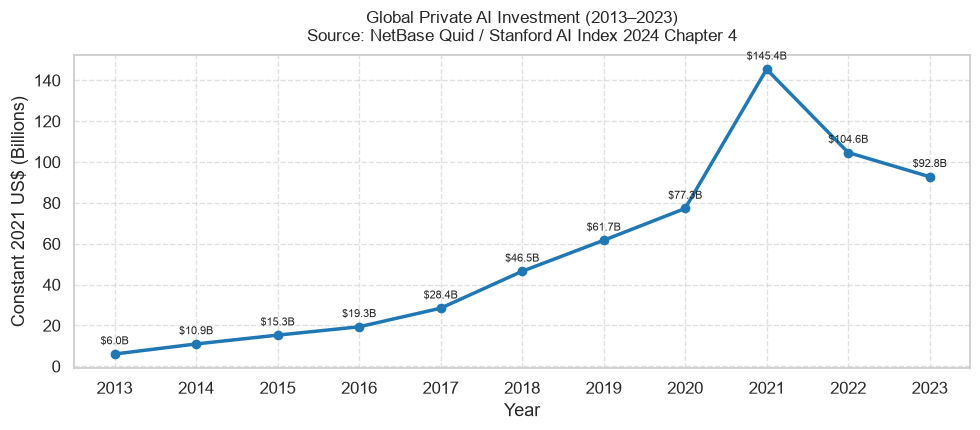

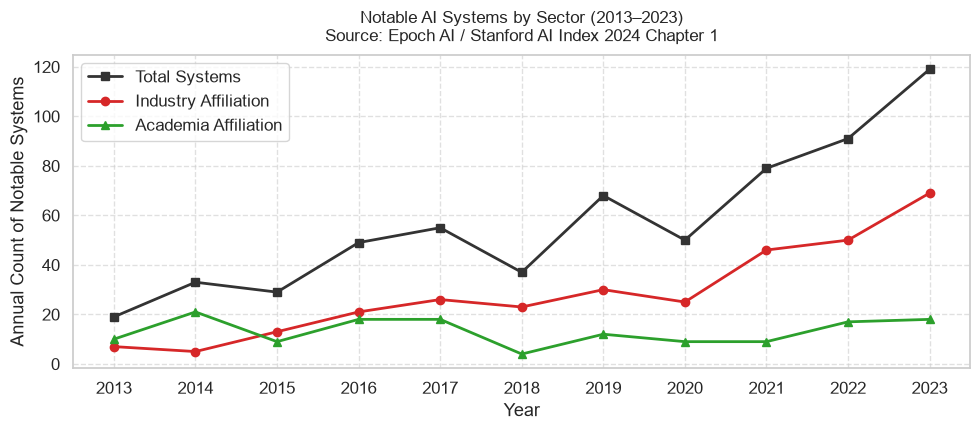

In [7]:
metrics_path = PROCESSED_DIR / 'metrics_validated.json'
if not metrics_path.exists():
    print('WARNING: metrics_validated.json not found.')
else:
    df_metrics = pd.DataFrame(json.load(open(metrics_path, encoding='utf-8')))
    print(f'Loaded {len(df_metrics)} validated metric observations across metrics:')
    print(df_metrics['metric_name'].value_counts())

    # 1. Private AI Investment (2013-2023)
    df_inv = df_metrics[df_metrics['metric_name'] == 'global_private_ai_investment_annual_constant_2021_usd_billions'].copy()
    df_inv['year'] = df_inv['period'].astype(int)
    df_inv = df_inv.sort_values('year')

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(df_inv['year'], df_inv['value'], marker='o', color='#1f77b4', linewidth=2.5, markersize=6)
    ax.set_title('Global Private AI Investment (2013–2023)\nSource: NetBase Quid / Stanford AI Index 2024 Chapter 4', fontsize=12, pad=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Constant 2021 US$ (Billions)')
    ax.set_xticks(df_inv['year'])
    ax.grid(True, linestyle='--', alpha=0.6)
    for _, r in df_inv.iterrows():
        ax.annotate(f"${r['value']:.1f}B", (r['year'], r['value']), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
    plt.tight_layout()
    plt.show()

    # 2. Notable AI Systems by Affiliation (2013-2023)
    aff_metrics = df_metrics[df_metrics['metric_name'].isin([
        'notable_ai_systems_annual_count_industry',
        'notable_ai_systems_annual_count_academia',
        'notable_ai_systems_annual_count_total'
    ])].copy()
    aff_metrics['year'] = aff_metrics['period'].astype(int)
    piv_aff = aff_metrics.pivot(index='year', columns='metric_name', values='value').sort_index()

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(piv_aff.index, piv_aff['notable_ai_systems_annual_count_total'], marker='s', label='Total Systems', color='#333333', linewidth=2)
    ax.plot(piv_aff.index, piv_aff['notable_ai_systems_annual_count_industry'], marker='o', label='Industry Affiliation', color='#d62728', linewidth=2)
    ax.plot(piv_aff.index, piv_aff['notable_ai_systems_annual_count_academia'], marker='^', label='Academia Affiliation', color='#2ca02c', linewidth=2)
    ax.set_title('Notable AI Systems by Sector (2013–2023)\nSource: Epoch AI / Stanford AI Index 2024 Chapter 1', fontsize=12, pad=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Annual Count of Notable Systems')
    ax.set_xticks(piv_aff.index)
    ax.legend(frameon=True)
    ax.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
